In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler


In [ ]:
rfm = pd.read_csv('/content/drive/MyDrive/segmentation_project/rfm.csv')
rfm.shape

(5878, 4)

In [ ]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,4921.53
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40


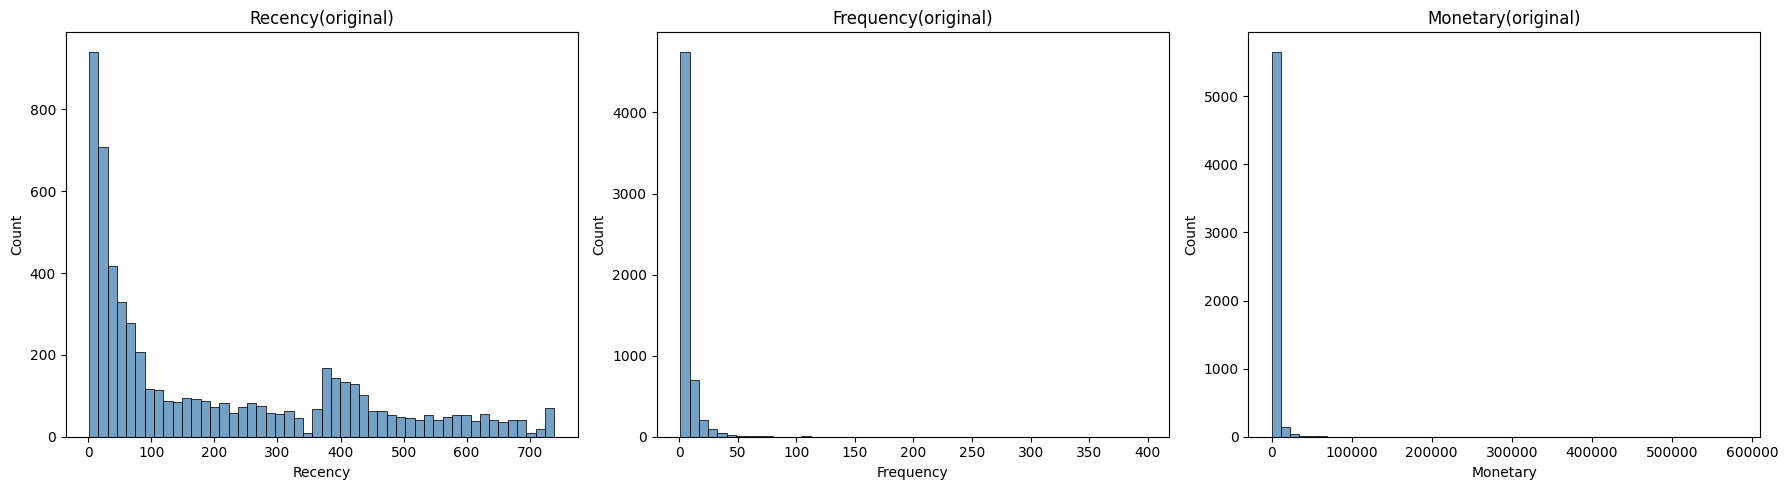

In [ ]:
features = ['Recency','Frequency','Monetary']
fig, axes = plt.subplots(1,3, figsize=(18,5))

for ax, feature in zip(axes, features):
  sns.histplot(rfm[feature], bins=50, ax=ax, color='steelblue')
  ax.set_title(feature + '(original)')

plt.tight_layout()
plt.show()


In [ ]:
rfm[features].skew().round(2)

,0
Recency,0.89
Frequency,12.64
Monetary,25.07


In [ ]:
rfm_log = rfm.copy()
rfm_log[features] = np.log1p(rfm_log[features])
rfm_log.head()

,Customer ID,Recency,Frequency,Monetary
0,12346,5.789960,2.564949,11.258774
1,12347,1.098612,2.197225,8.501578
2,12348,4.330733,1.791759,7.611051
3,12349,2.995732,1.609438,8.396085
4,12350,5.739793,0.693147,5.815324


In [ ]:
print("Skewness After log transform:")
print(rfm_log[features].skew().round(2))

Skewness After log transform:
Recency     -0.49
Frequency    1.00
Monetary     0.27
dtype: float64


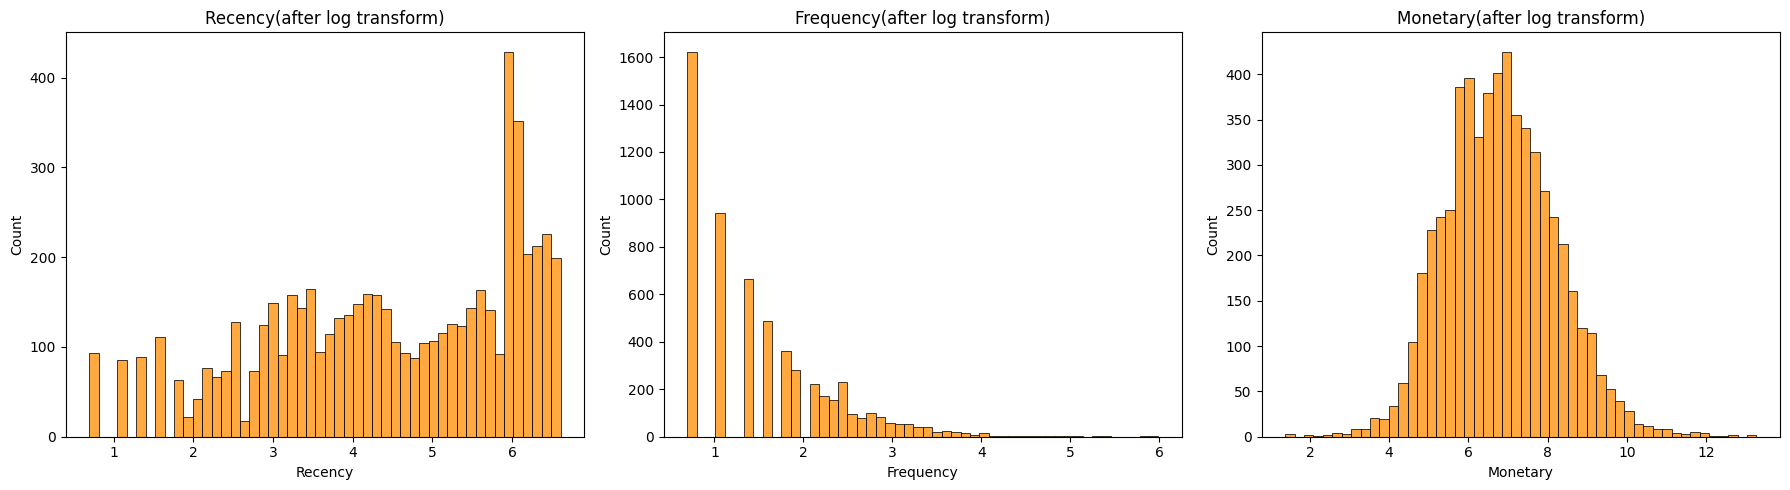

In [ ]:
fig, axes = plt.subplots(1,3, figsize=(18,5))
for ax, feature in zip(axes, features):
  sns.histplot(rfm_log[feature], bins=50, ax=ax, color='darkorange')
  ax.set_title(feature + '(after log transform)')
plt.tight_layout()
plt.show()



In [ ]:
scaler = StandardScaler()
scaled_values = scaler.fit_transform(rfm_log[features])
rfm_scaled = pd.DataFrame(scaled_values, columns=features)
rfm_scaled.insert(0, 'Customer ID', rfm['Customer ID'])
rfm_scaled.head()

,Customer ID,Recency,Frequency,Monetary
0,12346,0.856701,1.254496,3.206219
1,12347,-2.151979,0.800166,1.215993
2,12348,-0.079138,0.299207,0.573185
3,12349,-0.935308,0.073946,1.139846
4,12350,0.824527,-1.058146,-0.723024


In [ ]:
rfm_scaled[features].describe().round(2)

,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,-0.00,0.00,0.00
std,1.00,1.00,1.00
min,-2.41,-1.06,-3.93
25%,-0.74,-1.06,-0.71
50%,0.08,-0.20,-0.04
75%,0.95,0.65,0.65
max,1.38,5.48,4.66


In [ ]:
rfm_scaled.to_csv('/content/drive/MyDrive/segmentation_project/rfm_scaled.csv')